# A Leakage-Aware Stacked Ensemble Learning Framework for Coronary Artery Disease Prediction

In [1]:
!pip -q install imbalanced-learn catboost shap statsmodels openpyxl

In [2]:
import os, warnings, time, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef,
                             roc_auc_score, confusion_matrix, roc_curve, brier_score_loss,
                             classification_report)
from sklearn.calibration import calibration_curve
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from statsmodels.stats.proportion import proportion_confint
import shap

sns.set_style("whitegrid")

In [3]:
SEED          = 42
TEST_SIZE     = 0.20
OUTER_FOLDS   = 10        # outer CV for model comparison
INNER_FOLDS   = 5         # inner CV for RandomizedSearchCV
N_ITER        = 20        # RandomizedSearchCV iterations
N_BOOT        = 2000      # bootstrap resamples (test CIs, paired comparisons)
FAST_MODE     = False     # True = smaller models / fewer iterations, for a quick smoke test

# (a) Where is SMOTE placed relative to the StackingClassifier?
#     "inside"  = SMOTE inside each base learner; the stack's internal CV never sees synthetic rows (leakage-clean)
STACK_SMOTE_MODE = "inside"
# (b) Do the ensembles use RF/XGB with tuned hyper-parameters?
#     False = ensemble members use library defaults (CV estimates are fully nested / leakage-free)
USE_TUNED_IN_ENSEMBLES = False
# (c) SHAP computed on real training rows ("real") or on SMOTE-augmented rows ("smote")
SHAP_ROWS = "real"
RUN_ENSEMBLE_SHAP = True
THRESHOLD = 0.5    # decision threshold for class labels
OUT_DIR = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)

np.random.seed(SEED)

## 1. Load data and Stage-1 preprocessing (label-independent, full dataset)

In [4]:
DATA_PATH = "Z-Alizadeh sani dataset.xlsx"

raw = pd.read_excel(DATA_PATH, sheet_name=0)
print("Raw shape:", raw.shape)     # expected (303, 56): 55 predictors + 'Cath'
assert raw.shape == (303, 56), "Unexpected shape"
print(raw["Cath"].value_counts())
print("Missing values:", int(raw.isna().sum().sum()))

Raw shape: (303, 56)
Cath
Cad       216
Normal     87
Name: count, dtype: int64
Missing values: 0


In [5]:
df = raw.copy()

const_cols = [c for c in df.columns if c != "Cath" and df[c].nunique() == 1]
print("Constant columns removed:", const_cols)
df = df.drop(columns=const_cols)

# deterministic encodings (no information learned from data or labels)
df["Sex"] = df["Sex"].map({"Male": 1, "Fmale": 0})    # 'Fmale' is the spelling used in the dataset
df["VHD"] = df["VHD"].map({"N": 0, "mild": 1, "Moderate": 2, "Severe": 3})   # ordinal
yn_cols = [c for c in df.columns
           if c not in ("Cath", "BBB", "Sex", "VHD") and not pd.api.types.is_numeric_dtype(df[c])]   # text columns holding Y/N
for c in yn_cols:
    df[c] = df[c].map({"Y": 1, "N": 0})
df = pd.get_dummies(df, columns=["BBB"], prefix="BBB", dtype=int)    # non-ordinal -> one-hot
y_all = (df["Cath"] == "Cad").astype(int)      # CAD = 1 (positive, majority), Normal = 0
X_all = df.drop(columns="Cath").astype(float)

assert X_all.isna().sum().sum() == 0, "Encoding produced NaNs - check category spellings"
print("Predictors after Stage 1 (incl. BBB one-hot):", X_all.shape[1])
print("Original predictors: 55 -> minus 1 constant (54) -> BBB expands 1 column into 3 =", X_all.shape[1])

Constant columns removed: ['Exertional CP']
Predictors after Stage 1 (incl. BBB one-hot): 56
Original predictors: 55 -> minus 1 constant (54) -> BBB expands 1 column into 3 = 56


## 2. Stratified 80/20 split (test set locked until final evaluation)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
print(f"Train: {len(X_train)}  (CAD {int(y_train.sum())}, Normal {int((1-y_train).sum())})")
print(f"Test : {len(X_test)}  (CAD {int(y_test.sum())}, Normal {int((1-y_test).sum())})")
feature_names = list(X_all.columns)

Train: 242  (CAD 173, Normal 69)
Test : 61  (CAD 43, Normal 18)


## 3. Exploratory analysis (training partition only)

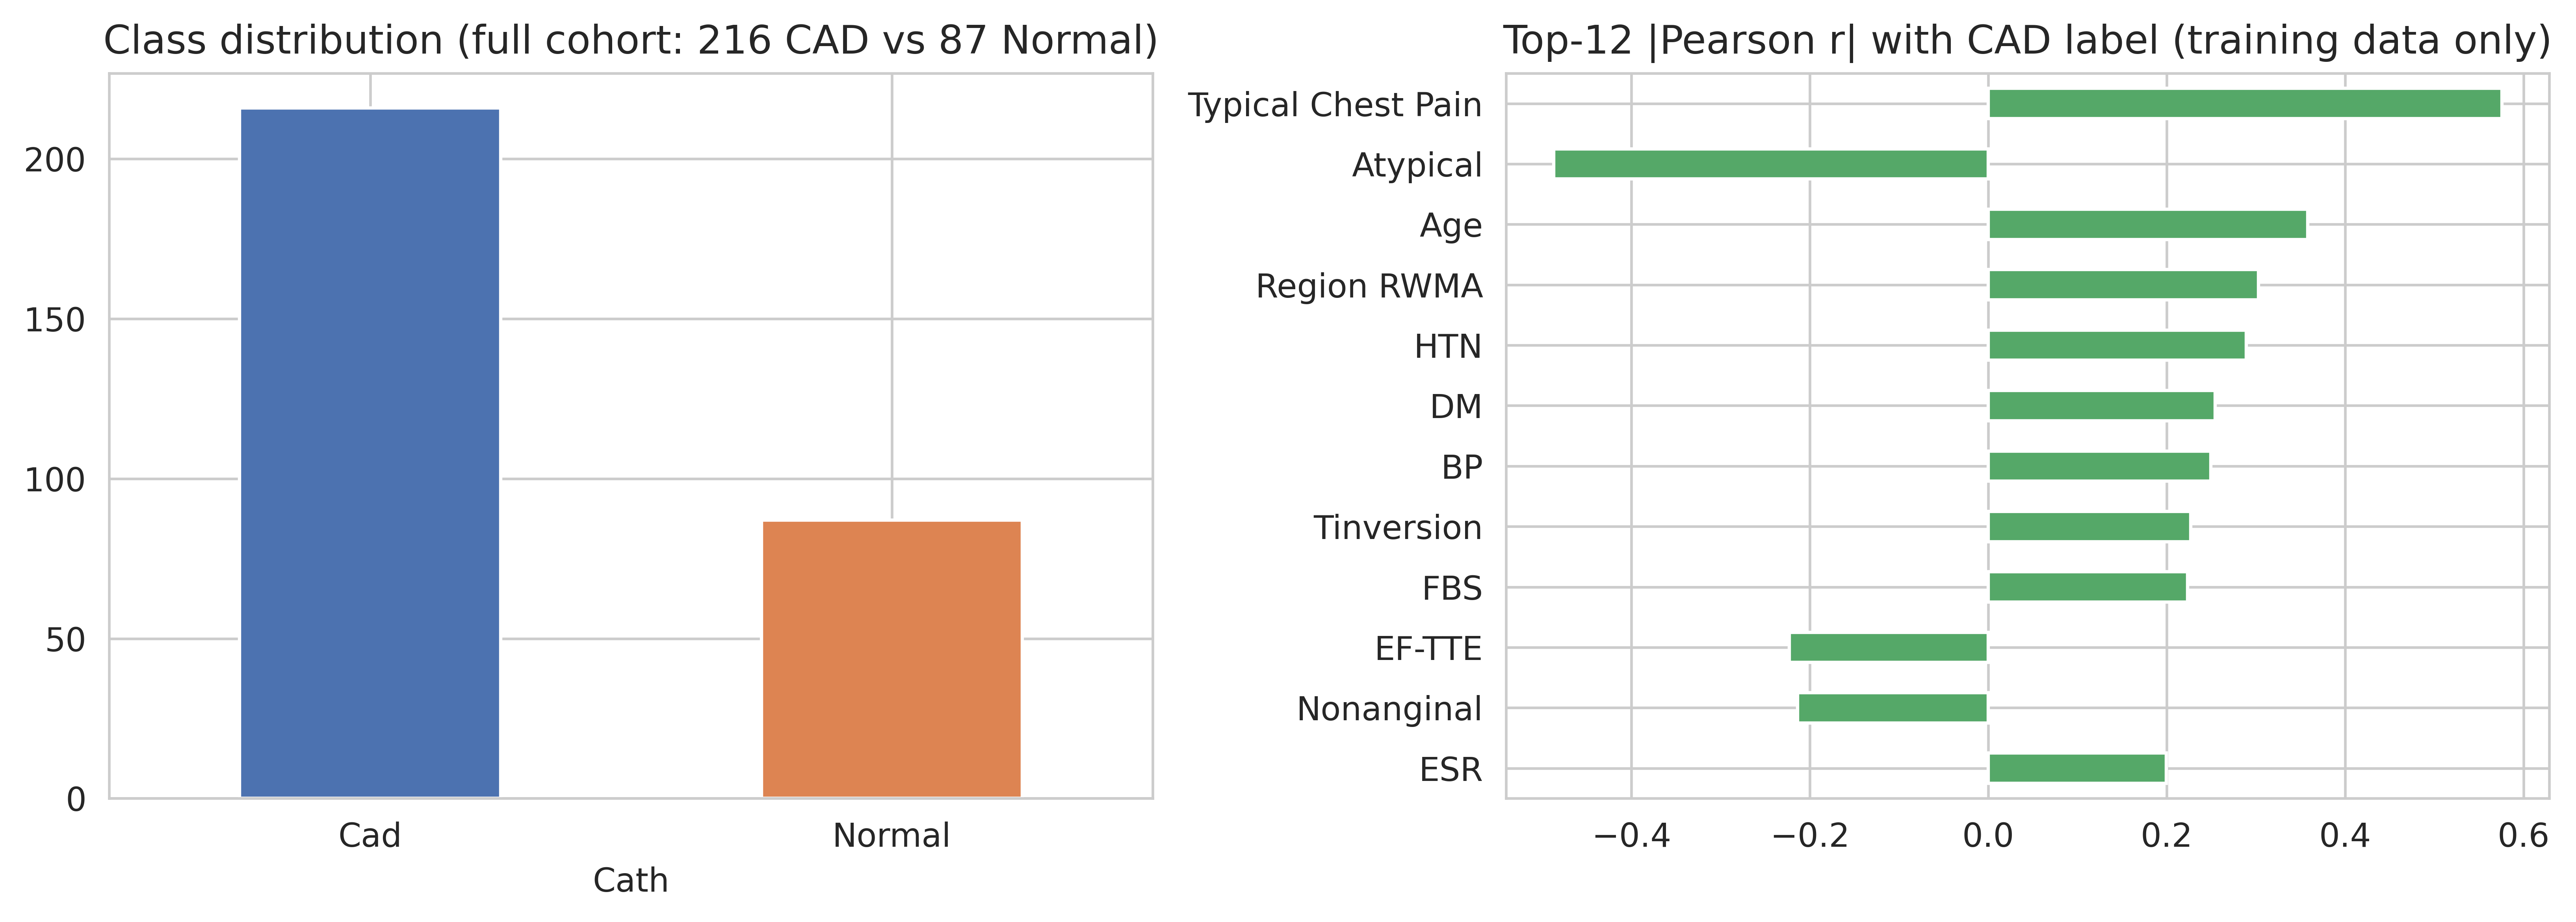

Typical Chest Pain    0.576
Atypical             -0.487
Age                   0.358
Region RWMA           0.303
HTN                   0.289
DM                    0.255
BP                    0.250
Tinversion            0.227
Name: Cath, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4),dpi=600)
raw["Cath"].value_counts().plot(kind="bar", ax=ax[0], color=["#4C72B0", "#DD8452"], rot=0)
ax[0].set_title("Class distribution (full cohort: 216 CAD vs 87 Normal)")
corr = X_train.assign(Cath=y_train).corr()["Cath"].drop("Cath").sort_values(key=abs, ascending=False)
corr.head(12)[::-1].plot(kind="barh", ax=ax[1], color="#55A868")
ax[1].set_title("Top-12 |Pearson r| with CAD label (training data only)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_eda.png", dpi=600)
plt.show()
print(corr.head(8).round(3))

## 4. Model definitions (Scale -> SMOTE -> classifier pipelines)

In [8]:
outer_cv = StratifiedKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=SEED)
def inner_cv(): return StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=SEED)

def base_learners(params=None):
    """Fresh instances of the 8 base learners (library defaults unless params given)."""
    params = params or {}
    n = 50 if FAST_MODE else None
    rf  = RandomForestClassifier(random_state=SEED, n_jobs=1, **({"n_estimators": n} if n else {}), **params.get("RF", {}))
    et  = ExtraTreesClassifier(random_state=SEED, n_jobs=1, **({"n_estimators": n} if n else {}))
    gb  = GradientBoostingClassifier(random_state=SEED, **({"n_estimators": n} if n else {}))
    xgb = XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1, verbosity=0,
                        **({"n_estimators": n} if n else {}), **params.get("XGB", {}))
    lgb = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1, **({"n_estimators": n} if n else {}))
    cat = CatBoostClassifier(random_seed=SEED, verbose=0, thread_count=1, allow_writing_files=False,
                             **({"iterations": 100} if FAST_MODE else {}))
    lr  = LogisticRegression(max_iter=5000, random_state=SEED)
    svm = SVC(kernel="rbf", probability=True, random_state=SEED)
    return {"Logistic Regression": lr, "SVM (RBF)": svm, "Random Forest": rf, "Extra Trees": et,
            "Gradient Boosting": gb, "XGBoost": xgb, "LightGBM": lgb, "CatBoost": cat}

def pipe(clf):
    return ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=SEED)), ("clf", clf)])

SEARCH_SPACE = {
    "RF":  {"clf__n_estimators": [100, 200, 300, 500], "clf__max_depth": [None, 3, 5, 8, 12],
            "clf__min_samples_split": [2, 5, 10]},
    "XGB": {"clf__n_estimators": [100, 200, 300, 500], "clf__max_depth": [2, 3, 4, 5, 6],
            "clf__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2]},
}
if FAST_MODE:
    SEARCH_SPACE["RF"]["clf__n_estimators"] = [30, 60]; SEARCH_SPACE["XGB"]["clf__n_estimators"] = [30, 60]
N_ITER_EFF = 3 if FAST_MODE else N_ITER

def tuned_search(clf, key, n_jobs):
    return RandomizedSearchCV(pipe(clf), SEARCH_SPACE[key], n_iter=N_ITER_EFF, cv=inner_cv(),
                              scoring="roc_auc", random_state=SEED, n_jobs=n_jobs, refit=True)

# (optional) ONE tuning run on the full training partition -> params used if USE_TUNED_IN_ENSEMBLES
tuned_params = {}
if USE_TUNED_IN_ENSEMBLES:
    for key, nm in [("RF", "Random Forest"), ("XGB", "XGBoost")]:
        s = tuned_search(base_learners()[nm], key, n_jobs=-1).fit(X_train, y_train)
        tuned_params[key] = {k.replace("clf__", ""): v for k, v in s.best_params_.items()}
    print("Tuned params used in ensembles:", tuned_params)

ENS_MEMBERS = ["Random Forest", "Extra Trees", "XGBoost", "LightGBM", "CatBoost"]
BAG_TRIO    = ["Random Forest", "Extra Trees", "Gradient Boosting"]
BOOST_TRIO  = ["XGBoost", "LightGBM", "CatBoost"]

def soft_voting(names):
    L = base_learners(tuned_params)
    return pipe(VotingClassifier([(n, L[n]) for n in names], voting="soft"))   # equal-weight probability averaging; no meta-learner

def stack(names):
    L = base_learners(tuned_params)
    meta = LogisticRegression(max_iter=5000, random_state=SEED)
    sc = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
    if STACK_SMOTE_MODE == "outside":
        return pipe(StackingClassifier([(n, L[n]) for n in names], final_estimator=meta, cv=sc, stack_method="predict_proba"))
    members = [(n, ImbPipeline([("smote", SMOTE(random_state=SEED)), ("clf", L[n])])) for n in names]
    return ImbPipeline([("scaler", StandardScaler()),
                        ("clf", StackingClassifier(members, final_estimator=meta, cv=sc, stack_method="predict_proba"))])

def build_models():
    L = base_learners(tuned_params); M = {}
    for nm in L:
        if nm == "Random Forest":  M[nm] = ("nested", tuned_search(L[nm], "RF", n_jobs=-1))
        elif nm == "XGBoost":      M[nm] = ("nested", tuned_search(L[nm], "XGB", n_jobs=-1))
        else:                      M[nm] = ("plain", pipe(L[nm]))
    M["Soft Voting (RF+ET+XGB+LGBM+CatBoost)"] = ("plain", soft_voting(ENS_MEMBERS))
    M["Full Stack (5 learners + LR meta)"]     = ("plain", stack(ENS_MEMBERS))
    M["Bagging-trio Stack (RF+ET+GB + LR meta)"] = ("plain", stack(BAG_TRIO))
    M["Boosting-trio Stack (XGB+LGBM+CatBoost + LR meta)"] = ("plain", stack(BOOST_TRIO))
    return M
MODELS = build_models()
print(len(MODELS), "configurations:", *MODELS, sep="\n  ")

12
  configurations:
  Logistic Regression
  SVM (RBF)
  Random Forest
  Extra Trees
  Gradient Boosting
  XGBoost
  LightGBM
  CatBoost
  Soft Voting (RF+ET+XGB+LGBM+CatBoost)
  Full Stack (5 learners + LR meta)
  Bagging-trio Stack (RF+ET+GB + LR meta)
  Boosting-trio Stack (XGB+LGBM+CatBoost + LR meta)


## 5. Leakage-controlled 10-fold cross-validation

In [9]:
def metrics(y_true, p, thr=THRESHOLD):
    yhat = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y_true, yhat).ravel()
    return {"AUC": roc_auc_score(y_true, p), "Accuracy": accuracy_score(y_true, yhat),
            "Precision": precision_score(y_true, yhat), "Recall": recall_score(y_true, yhat),
            "Specificity": tn / (tn + fp), "F1": f1_score(y_true, yhat), "MCC": matthews_corrcoef(y_true, yhat)}

oof, rows = {}, []
for name, (kind, est) in MODELS.items():
    t0 = time.time()
    # nested models: parallelism lives in the inner search -> outer n_jobs=1; others: parallelise outer folds
    p = cross_val_predict(est, X_train, y_train, cv=outer_cv, method="predict_proba",
                          n_jobs=1 if kind == "nested" else -1)[:, 1]
    oof[name] = p; rows.append({"Model": name, **metrics(y_train.values, p)})
    print(f"{name:<55s} AUC={rows[-1]['AUC']:.3f}  ({time.time()-t0:.0f}s)")

cv_table = pd.DataFrame(rows).set_index("Model").sort_values("AUC", ascending=False).round(3)
cv_table.to_csv(f"{OUT_DIR}/cv_results_all.csv")

Logistic Regression                                     AUC=0.911  (7s)
SVM (RBF)                                               AUC=0.897  (1s)
Random Forest                                           AUC=0.931  (382s)
Extra Trees                                             AUC=0.923  (2s)
Gradient Boosting                                       AUC=0.923  (3s)
XGBoost                                                 AUC=0.925  (153s)
LightGBM                                                AUC=0.923  (10s)
CatBoost                                                AUC=0.933  (36s)
Soft Voting (RF+ET+XGB+LGBM+CatBoost)                   AUC=0.936  (40s)
Full Stack (5 learners + LR meta)                       AUC=0.932  (401s)
Bagging-trio Stack (RF+ET+GB + LR meta)                 AUC=0.931  (64s)
Boosting-trio Stack (XGB+LGBM+CatBoost + LR meta)       AUC=0.924  (394s)


In [10]:
base_names = list(base_learners().keys())
print("TABLE 2 - base classifiers (10-fold OOF, training partition)")
display(cv_table.loc[[m for m in cv_table.index if m in base_names]])
print("TABLE 3 - ensembles (10-fold OOF, training partition)")
display(cv_table.loc[[m for m in cv_table.index if m not in base_names]])

# precision vs recall direction (manuscript Section 3.2)
pr = cv_table.loc[[m for m in cv_table.index if m in base_names], ["Precision", "Recall"]]
print("Recall > Precision for:", list(pr.index[pr.Recall > pr.Precision]))
print("Precision > Recall for:", list(pr.index[pr.Precision > pr.Recall]))

TABLE 2 - base classifiers (10-fold OOF, training partition)


,AUC,Accuracy,Precision,Recall,Specificity,F1,MCC
Model,,,,,,,
CatBoost,0.933,0.884,0.924,0.913,0.812,0.919,0.719
Random Forest,0.931,0.868,0.912,0.902,0.783,0.907,0.679
XGBoost,0.925,0.876,0.923,0.902,0.812,0.912,0.702
Gradient Boosting,0.923,0.876,0.913,0.913,0.783,0.913,0.696
Extra Trees,0.923,0.868,0.903,0.913,0.754,0.908,0.673
LightGBM,0.923,0.897,0.920,0.936,0.797,0.928,0.744
Logistic Regression,0.911,0.843,0.914,0.861,0.797,0.887,0.634
SVM (RBF),0.897,0.855,0.875,0.931,0.667,0.902,0.632


TABLE 3 - ensembles (10-fold OOF, training partition)


,AUC,Accuracy,Precision,Recall,Specificity,F1,MCC
Model,,,,,,,
Soft Voting (RF+ET+XGB+LGBM+CatBoost),0.936,0.884,0.910,0.931,0.768,0.920,0.712
Full Stack (5 learners + LR meta),0.932,0.884,0.910,0.931,0.768,0.920,0.712
Bagging-trio Stack (RF+ET+GB + LR meta),0.931,0.876,0.899,0.931,0.739,0.915,0.689
Boosting-trio Stack (XGB+LGBM+CatBoost + LR meta),0.924,0.884,0.910,0.931,0.768,0.920,0.712


Recall > Precision for: ['Extra Trees', 'LightGBM', 'SVM (RBF)']
Precision > Recall for: ['CatBoost', 'Random Forest', 'XGBoost', 'Logistic Regression']


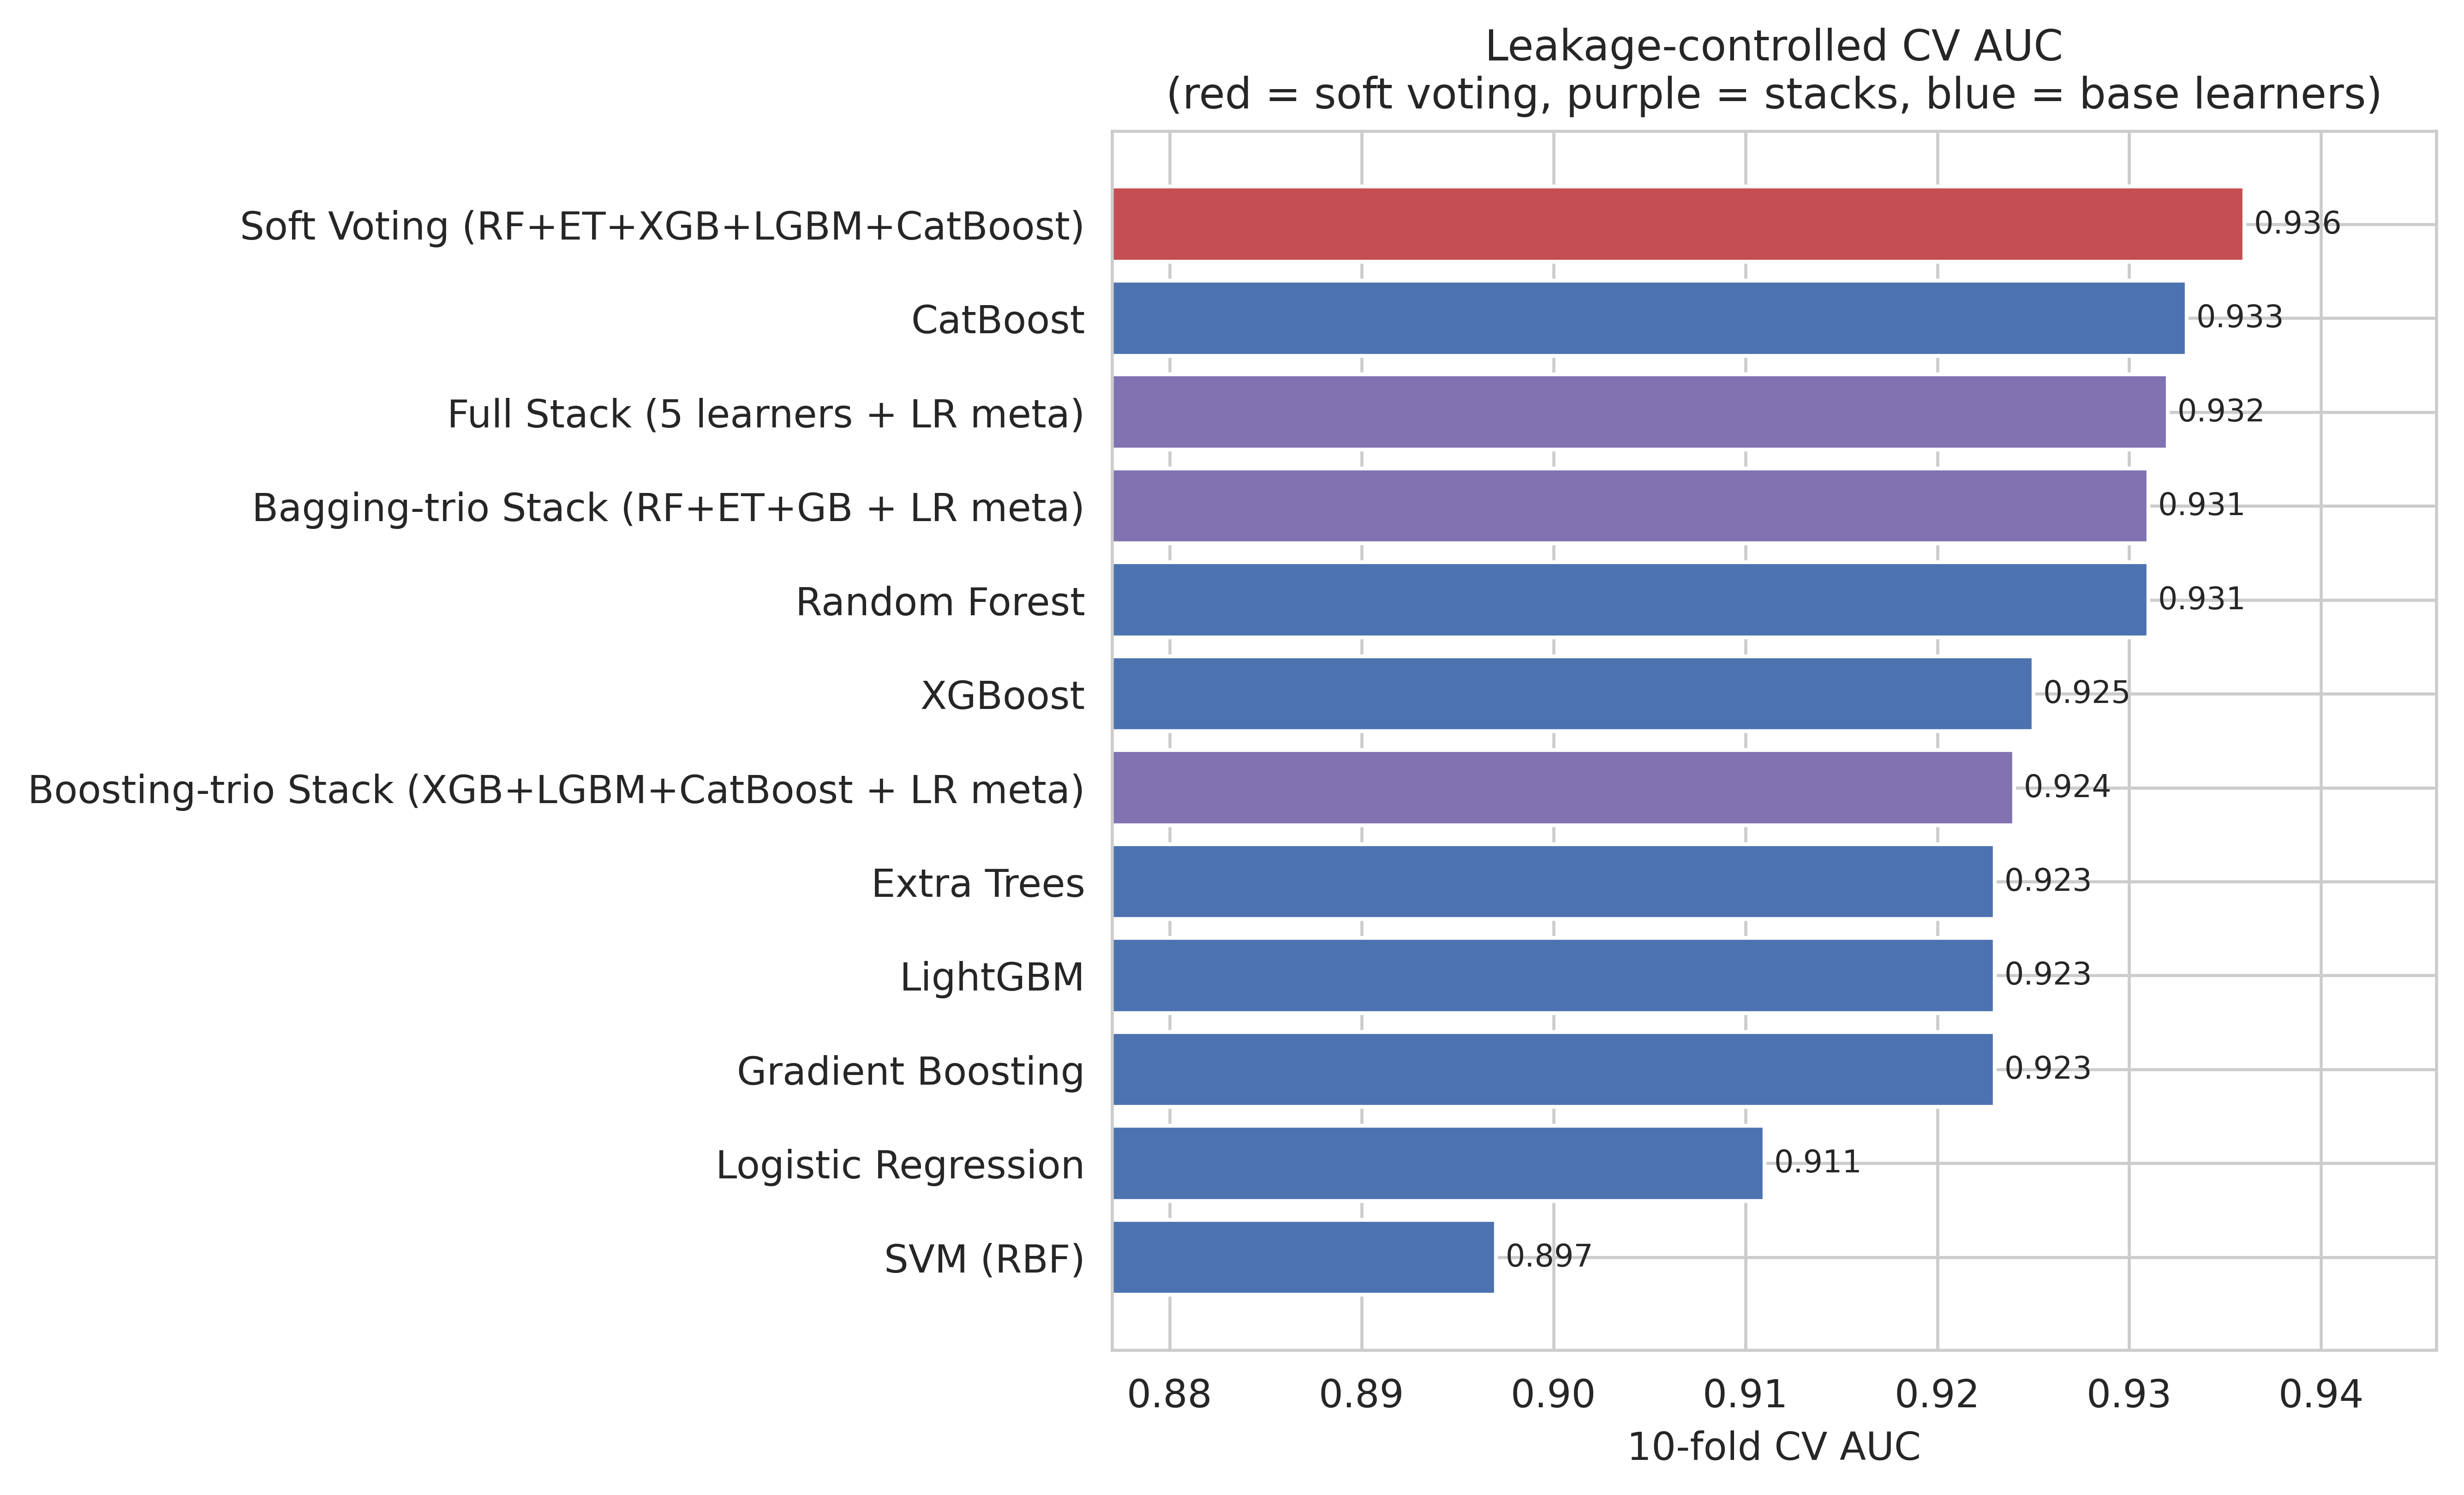

In [18]:
# Figure: CV AUC of all configurations
order = cv_table["AUC"].sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5),dpi=600)
cols = ["#C44E52" if "Soft Voting" in m else ("#8172B2" if "Stack" in m else "#4C72B0") for m in order.index]
ax.barh(order.index, order.values, color=cols)
ax.set_xlim(max(0.85, order.min() - 0.02), min(1.0, order.max() + 0.01)); ax.set_xlabel("10-fold CV AUC")
for i, v in enumerate(order.values): ax.text(v + 0.0005, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_title("Leakage-controlled CV AUC\n(red = soft voting, purple = stacks, blue = base learners)", fontsize=11)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig4_cv_auc.png", dpi=600, bbox_inches="tight")
plt.show()

### 5b. Paired bootstrap on out-of-fold predictions
Paired bootstrap of the AUC difference between the best configuration and each other.

In [12]:
def paired_boot_auc(y, pa, pb, B=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); y = np.asarray(y); n = len(y); d = []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if len(np.unique(y[i])) < 2: continue
        d.append(roc_auc_score(y[i], pa[i]) - roc_auc_score(y[i], pb[i]))
    d = np.array(d); return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5), 2*min((d<=0).mean(), (d>=0).mean())

best_name = cv_table["AUC"].idxmax(); print("Best configuration by CV AUC:", best_name)
res = []
for m in cv_table.index:
    if m == best_name: continue
    mu, lo, hi, p = paired_boot_auc(y_train.values, oof[best_name], oof[m])
    res.append({"Comparator": m, "dAUC (best - other)": mu, "95% CI low": lo, "95% CI high": hi, "approx. p": p})
paired_df = pd.DataFrame(res).round(4)
paired_df.to_csv(f"{OUT_DIR}/paired_bootstrap_auc.csv", index=False)
display(paired_df)

Best configuration by CV AUC: Soft Voting (RF+ET+XGB+LGBM+CatBoost)


,Comparator,dAUC (best - other),95% CI low,95% CI high,approx. p
0,CatBoost,0.0028,-0.0035,0.0098,0.378
1,Full Stack (5 learners + LR meta),0.0040,-0.0026,0.0118,0.264
2,Random Forest,0.0045,-0.0126,0.0201,0.559
3,Bagging-trio Stack (RF+ET+GB + LR meta),0.0050,-0.0079,0.0169,0.409
4,XGBoost,0.0101,-0.0020,0.0237,0.102
5,Boosting-trio Stack (XGB+LGBM+CatBoost + LR meta),0.0119,-0.0049,0.0309,0.172
6,Gradient Boosting,0.0121,-0.0080,0.0310,0.202
7,Extra Trees,0.0128,-0.0049,0.0318,0.164
8,LightGBM,0.0125,-0.0026,0.0293,0.116
9,Logistic Regression,0.0253,-0.0021,0.0549,0.069


## 6. Single evaluation of the selected model on the locked test set

Selected model: Soft Voting (RF+ET+XGB+LGBM+CatBoost)
Confusion matrix  TP=39  FN=4  TN=13  FP=5


,Value,95% CI
Accuracy,0.852,"[0.754, 0.934] (bootstrap)"
Precision,0.886,n/a
Recall (sensitivity),0.907,"[0.784, 0.963] (Wilson)"
Specificity,0.722,"[0.491, 0.875] (Wilson)"
F1,0.897,n/a
AUC-ROC,0.881,"[0.771, 0.970] (bootstrap)"
MCC,0.640,n/a


              precision    recall  f1-score   support

      Normal       0.76      0.72      0.74        18
         CAD       0.89      0.91      0.90        43

    accuracy                           0.85        61
   macro avg       0.83      0.81      0.82        61
weighted avg       0.85      0.85      0.85        61



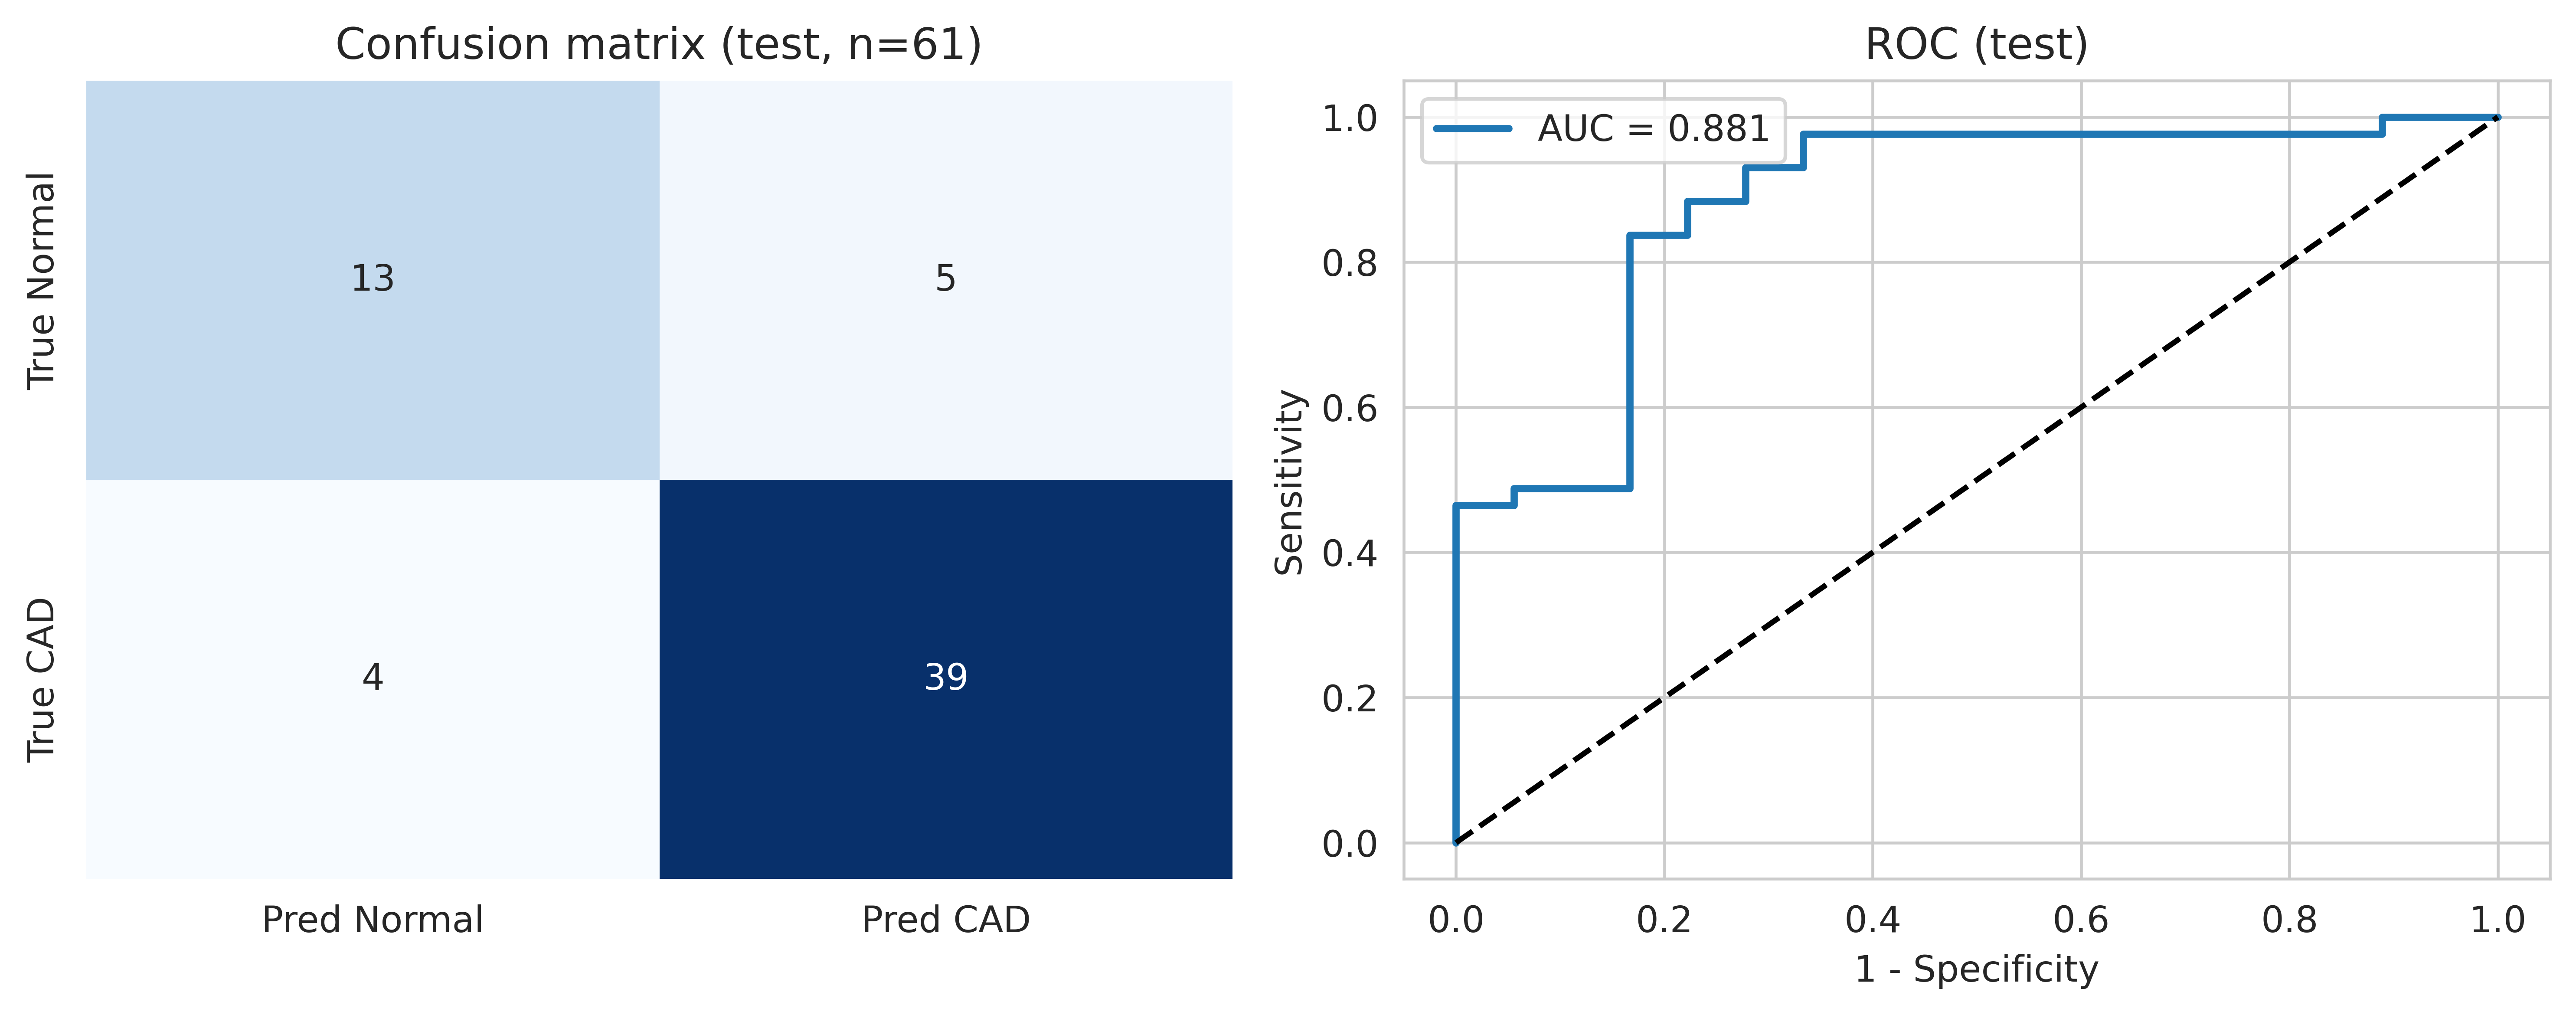

CV AUC 0.936  vs  test AUC 0.881; test CI contains CV value: True


In [13]:
final_name = best_name
final_est = MODELS[final_name][1]
final_est.fit(X_train, y_train)     # refit on the full training partition (SMOTE applied inside the pipeline)
p_test = final_est.predict_proba(X_test)[:, 1]
yhat = (p_test >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, yhat).ravel()
m_test = metrics(y_test.values, p_test)

# bootstrap 95% CIs for AUC and accuracy
rng = np.random.default_rng(SEED); yt = y_test.values; aucs, accs = [], []
for _ in range(N_BOOT):
    i = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[i])) < 2: continue
    aucs.append(roc_auc_score(yt[i], p_test[i])); accs.append(accuracy_score(yt[i], yhat[i]))
auc_ci, acc_ci = np.percentile(aucs, [2.5, 97.5]), np.percentile(accs, [2.5, 97.5])
sens_ci = proportion_confint(tp, tp + fn, method="wilson"); spec_ci = proportion_confint(tn, tn + fp, method="wilson")

print(f"Selected model: {final_name}")
print(f"Confusion matrix  TP={tp}  FN={fn}  TN={tn}  FP={fp}")
test_table = pd.DataFrame({
    "Value": [m_test["Accuracy"], m_test["Precision"], m_test["Recall"], m_test["Specificity"], m_test["F1"], m_test["AUC"], m_test["MCC"]],
    "95% CI": [f"[{acc_ci[0]:.3f}, {acc_ci[1]:.3f}] (bootstrap)", "n/a", f"[{sens_ci[0]:.3f}, {sens_ci[1]:.3f}] (Wilson)",
               f"[{spec_ci[0]:.3f}, {spec_ci[1]:.3f}] (Wilson)", "n/a", f"[{auc_ci[0]:.3f}, {auc_ci[1]:.3f}] (bootstrap)", "n/a"]},
    index=["Accuracy", "Precision", "Recall (sensitivity)", "Specificity", "F1", "AUC-ROC", "MCC"])
test_table["Value"] = test_table["Value"].round(3); display(test_table); test_table.to_csv(f"{OUT_DIR}/test_results.csv")
print(classification_report(y_test, yhat, target_names=["Normal", "CAD"], digits=2))

fig, ax = plt.subplots(1, 2, figsize=(10, 4),dpi=600)
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Pred Normal", "Pred CAD"], yticklabels=["True Normal", "True CAD"]); ax[0].set_title("Confusion matrix (test, n=61)")
fpr, tpr, _ = roc_curve(y_test, p_test); ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {m_test['AUC']:.3f}")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_xlabel("1 - Specificity"); ax[1].set_ylabel("Sensitivity"); ax[1].legend(); ax[1].set_title("ROC (test)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig5_test_eval.png", dpi=600)
plt.show()

# gap between CV and test estimates
print(f"CV AUC {cv_table.loc[final_name,'AUC']:.3f}  vs  test AUC {m_test['AUC']:.3f}; test CI contains CV value: "
      f"{auc_ci[0] <= cv_table.loc[final_name,'AUC'] <= auc_ci[1]}")

### 6b. Calibration of the selected model to address the calibration limitation

Brier score  OOF (train CV): 0.087   test: 0.115


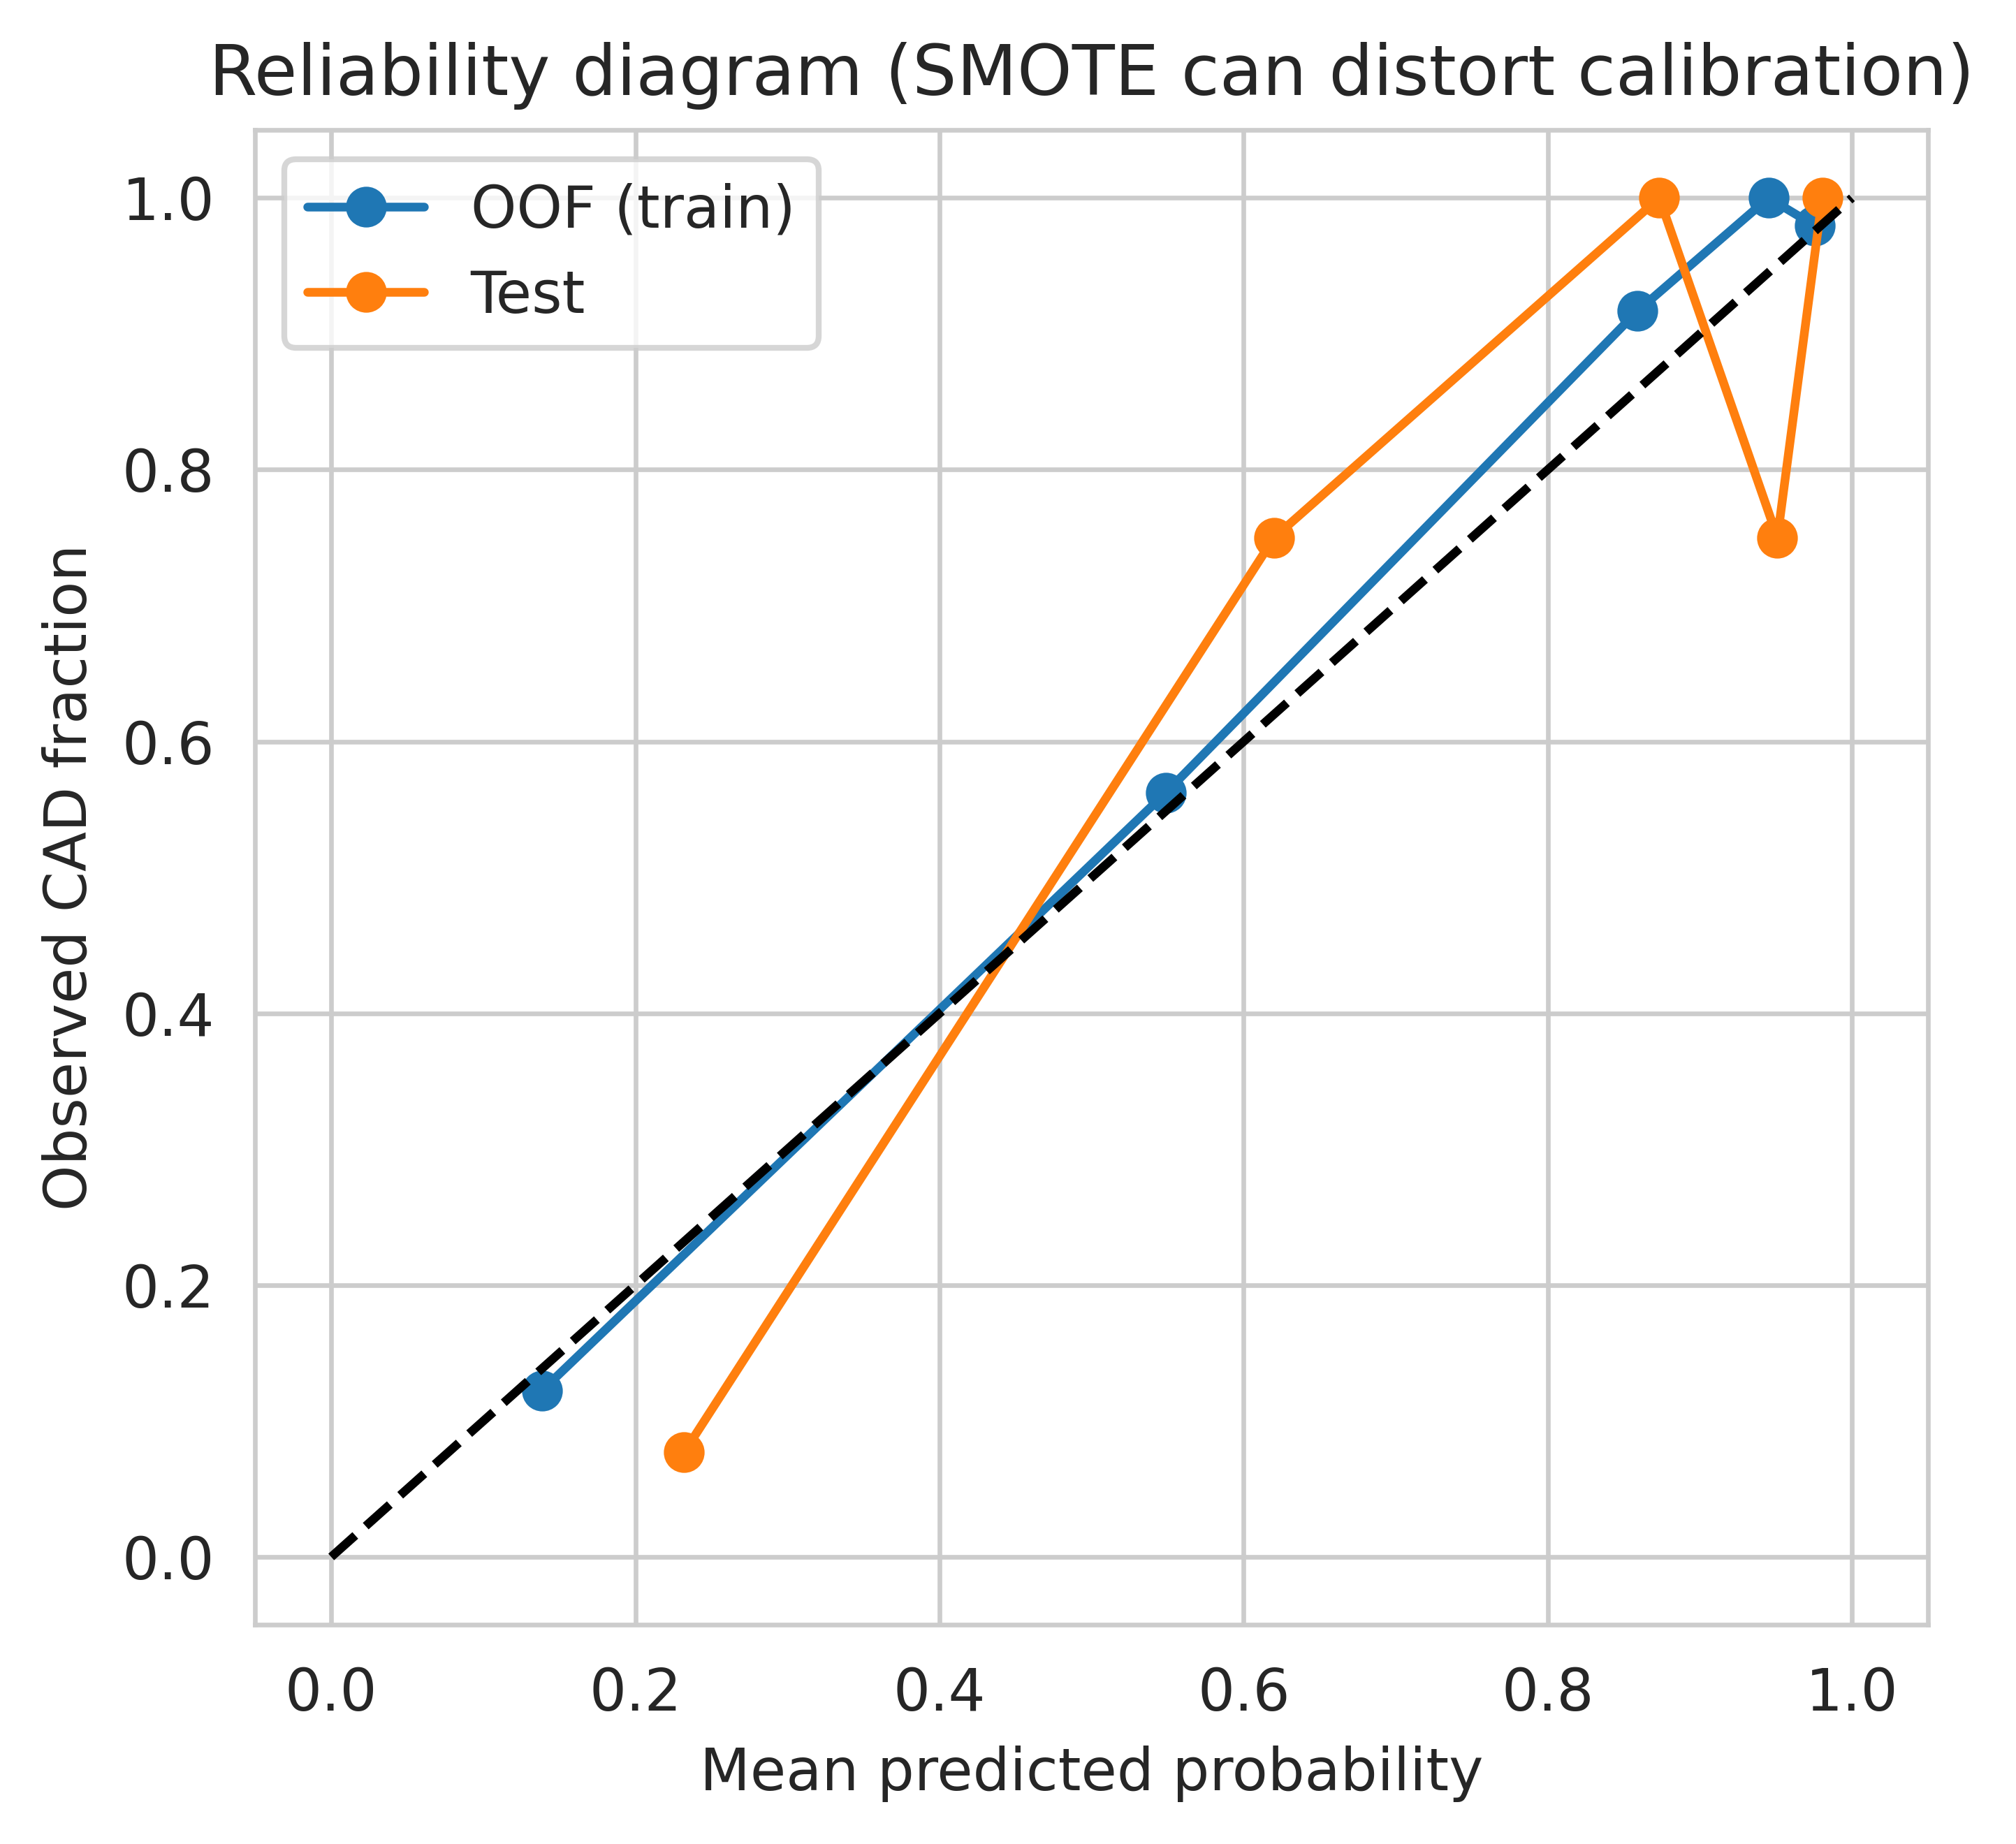

In [14]:
print(f"Brier score  OOF (train CV): {brier_score_loss(y_train, oof[final_name]):.3f}   test: {brier_score_loss(y_test, p_test):.3f}")
fig, ax = plt.subplots(figsize=(4.8, 4.5),dpi=600)
for lab, yy, pp in [("OOF (train)", y_train.values, oof[final_name]), ("Test", y_test.values, p_test)]:
    fo, mp = calibration_curve(yy, pp, n_bins=5, strategy="quantile")
    ax.plot(mp, fo, "o-", label=lab)
ax.plot([0, 1], [0, 1], "k--")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed CAD fraction")
ax.legend()
ax.set_title("Reliability diagram (SMOTE can distort calibration)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_calibration.png", dpi=600)
plt.show()

## 7. SHAP analysis of the XGBoost base learner & Soft-voting Ensemble
XGBoost is refitted on the SMOTE-balanced training data; TreeSHAP values are in log-odds units.

XGBoost params used for SHAP model: {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.2}
TABLE 5 - Top 15 features (XGBoost base learner; log-odds)


,Feature,Mean |SHAP|
1,Typical Chest Pain,1.988
2,EF-TTE,0.905
3,ESR,0.639
4,Age,0.583
5,Region RWMA,0.579
6,TG,0.482
7,FBS,0.430
8,HTN,0.402
9,Tinversion,0.313
10,VHD,0.291


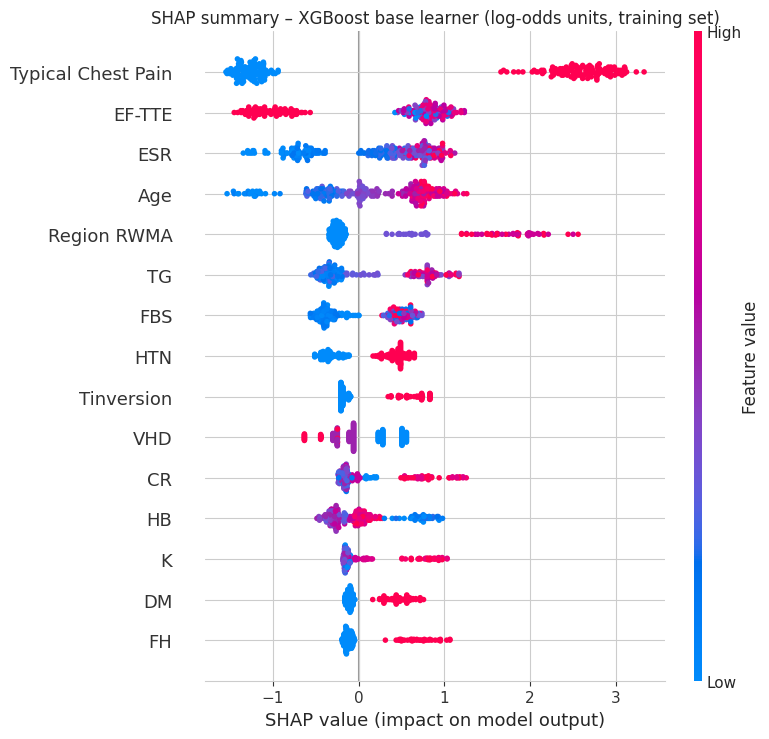

In [20]:
xgb_params = tuned_params.get("XGB")
if xgb_params is None:        # tune once on training data only (inner CV; test set untouched)
    s = tuned_search(base_learners()["XGBoost"], "XGB", n_jobs=-1).fit(X_train, y_train)
    xgb_params = {k.replace("clf__", ""): v for k, v in s.best_params_.items()}
print("XGBoost params used for SHAP model:", xgb_params)

scaler = StandardScaler().fit(X_train)
Xtr_s = scaler.transform(X_train)
Xres, yres = SMOTE(random_state=SEED).fit_resample(Xtr_s, y_train)
n = 50 if FAST_MODE else None
xgb_shap = XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1, verbosity=0,
                         **({"n_estimators": n} if (n and "n_estimators" not in xgb_params) else {}), **xgb_params).fit(Xres, yres)

explainer = shap.TreeExplainer(xgb_shap)
X_expl_s = Xres if SHAP_ROWS == "smote" else Xtr_s
sv = explainer.shap_values(X_expl_s)
X_disp = pd.DataFrame(scaler.inverse_transform(X_expl_s) if SHAP_ROWS == "real" else Xres, columns=feature_names)
shap_tab = (pd.DataFrame({"Feature": feature_names, "Mean |SHAP|": np.abs(sv).mean(0)})
            .sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True))
shap_tab.index += 1; shap_tab["Mean |SHAP|"] = shap_tab["Mean |SHAP|"].round(3)
print("TABLE 5 - Top 15 features (XGBoost base learner; log-odds)")
display(shap_tab.head(15))
shap_tab.to_csv(f"{OUT_DIR}/shap_xgb_table.csv")

shap.summary_plot(sv, X_disp, feature_names=feature_names, max_display=15, show=False)
plt.title("SHAP summary – XGBoost base learner (log-odds units, training set)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig6_shap_summary.png", dpi=600, bbox_inches="tight")
plt.show()

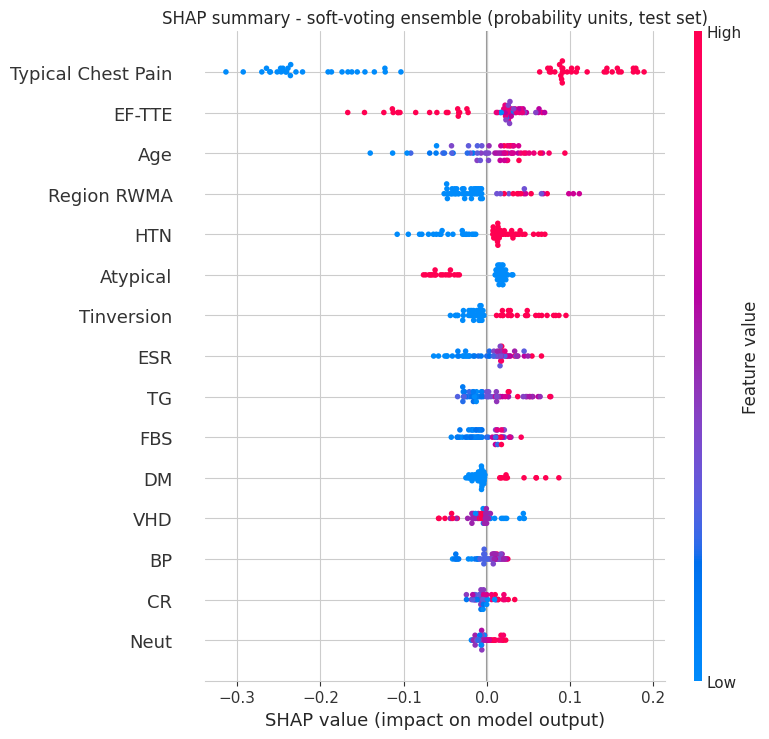

In [19]:
# Figure: SHAP summary for the soft-voting ensemble (probability units, 61 test patients)
if "ens_sv" in globals():
    X_test_disp = pd.DataFrame(sc_f.inverse_transform(Xt_s), columns=feature_names)
    shap.summary_plot(ens_sv.values, X_test_disp, feature_names=feature_names,
                      max_display=15, show=False)
    plt.title("SHAP summary - soft-voting ensemble (probability units, test set)")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/fig7_shap_ensemble_summary.png", dpi=600, bbox_inches="tight")
    plt.show()

In [16]:
# Ensemble-level SHAP for the selected soft-voting model (model-agnostic permutation SHAP, probability space)
if RUN_ENSEMBLE_SHAP and "Soft Voting" in final_name:
    try:
        sc_f, vote_f = final_est.named_steps["scaler"], final_est.named_steps["clf"]
        f = lambda Z: vote_f.predict_proba(Z)[:, 1]
        bg = shap.maskers.Independent(sc_f.transform(X_train), max_samples=50)
        expl = shap.PermutationExplainer(f, bg, seed=SEED)
        Xt_s = sc_f.transform(X_test)
        ens_sv = expl(Xt_s, max_evals=2 * Xt_s.shape[1] + 1 if FAST_MODE else 4 * Xt_s.shape[1] + 1)
        ens_tab = (pd.DataFrame({"Feature": feature_names, "Mean |SHAP| (prob.)": np.abs(ens_sv.values).mean(0)})
                   .sort_values("Mean |SHAP| (prob.)", ascending=False).reset_index(drop=True))
        ens_tab.index += 1
        print("Ensemble-level SHAP on the test set (probability units) - top 15")
        display(ens_tab.head(15).round(4))
        ens_tab.to_csv(f"{OUT_DIR}/shap_ensemble_table.csv")
        top_x, top_e = set(shap_tab.Feature.head(10)), set(ens_tab.Feature.head(10))
        print("Overlap of top-10 features (XGBoost base learner vs ensemble):", sorted(top_x & top_e))
    except Exception as e:
        print("Ensemble SHAP skipped:", repr(e))

PermutationExplainer explainer: 62it [00:12,  1.11it/s]

Ensemble-level SHAP on the test set (probability units) - top 15


,Feature,Mean |SHAP| (prob.)
1,Typical Chest Pain,0.1611
2,EF-TTE,0.0470
3,Age,0.0355
4,Region RWMA,0.0332
5,HTN,0.0330
6,Atypical,0.0288
7,Tinversion,0.0277
8,ESR,0.0254
9,TG,0.0236
10,FBS,0.0173


Overlap of top-10 features (XGBoost base learner vs ensemble): ['Age', 'EF-TTE', 'ESR', 'FBS', 'HTN', 'Region RWMA', 'TG', 'Tinversion', 'Typical Chest Pain']
